# Analysis 5: Final Visualizations and Findings

## Objective
To consolidate the findings from the previous analyses and develop clear, presentation-ready visualizations that communicate important patterns in natural disasters.

## Key Areas
1. Disaster frequency by type.
2. Disaster impact and destructiveness.
3. Historical trends and decadal patterns.
4. Relationships between disaster frequency and severity.
5. Reporting coverage and data limitations.

## Expected Outcomes
- A collection of polished visualizations.
- Evidence-based key findings.
- Exported summary tables for the dashboard team.
- A consolidated set of visualizations for the project presentation.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 7)
plt.rcParams["font.size"] = 11

ROOT = Path.cwd()

if not (ROOT / "data" / "processed").exists():
    ROOT = ROOT.parent

DATA_DIR = ROOT / "data" / "processed"
OUTPUT_DIR = ROOT / "analysis" / "outputs"
VIS_DIR = ROOT / "visualizations" / "final"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
VIS_DIR.mkdir(parents=True, exist_ok=True)

events = pd.read_csv(
    DATA_DIR / "natural_disaster_events.csv",
    encoding="utf-8-sig"
)

type_summary = pd.read_csv(
    DATA_DIR / "natural_disaster_type_summary.csv",
    encoding="utf-8-sig"
)

print("Events loaded:", events.shape)
print("Disaster types:", events["Disaster Type"].nunique())

Events loaded: (15727, 35)
Disaster types: 15


In [2]:
# Convert impact and date columns into numeric values
numeric_columns = [
    "Total Deaths",
    "Total Affected",
    "Total Damage, Adjusted (million US$)",
    "Start Year"
]

for col in numeric_columns:
    events[col] = pd.to_numeric(events[col], errors="coerce")

# Create decade from Start Year
events["Decade"] = (events["Start Year"] // 10 * 10)

# Frequency by disaster type
frequency = (
    events.groupby("Disaster Type")["Event ID"]
    .nunique()
    .sort_values(ascending=False)
    .reset_index(name="Unique Events")
)

# Impact summary by disaster type
impact_summary = (
    events.groupby("Disaster Type")
    .agg(
        Unique_Events=("Event ID", "nunique"),
        Reported_Deaths=("Total Deaths", "count"),
        Average_Deaths=("Total Deaths", "mean"),
        Reported_Affected=("Total Affected", "count"),
        Average_Affected=("Total Affected", "mean"),
        Reported_Damage=("Total Damage, Adjusted (million US$)", "count"),
        Average_Damage=("Total Damage, Adjusted (million US$)", "mean")
    )
    .reset_index()
)

# Yearly frequency
yearly_frequency = (
    events.dropna(subset=["Start Year"])
    .groupby("Start Year")["Event ID"]
    .nunique()
    .reset_index(name="Unique Events")
)

# Decadal frequency
decadal_frequency = (
    events.dropna(subset=["Decade"])
    .groupby("Decade")["Event ID"]
    .nunique()
    .reset_index(name="Unique Events")
)

print("Final summaries prepared successfully!")
display(frequency.head())
display(impact_summary.head())

Final summaries prepared successfully!


,Disaster Type,Unique Events
0,Flood,5814
1,Storm,4026
2,Earthquake,1573
3,Epidemic,1447
4,Mass movement (wet),867


,Disaster Type,Unique_Events,Reported_Deaths,Average_Deaths,Reported_Affected,Average_Affected,Reported_Damage,Average_Damage
0,Animal incident,1,1,12.000000,1,5.000000e+00,0,NaN
1,Drought,647,67,175139.597015,477,6.349540e+06,205,2228.702302
2,Earthquake,1573,1190,2051.194958,1325,1.923459e+05,626,2881.017883
3,Epidemic,1447,1243,7747.338697,1257,4.046467e+04,1,0.061000
4,Extreme temperature,433,364,1093.307692,181,7.813080e+05,60,2391.096350


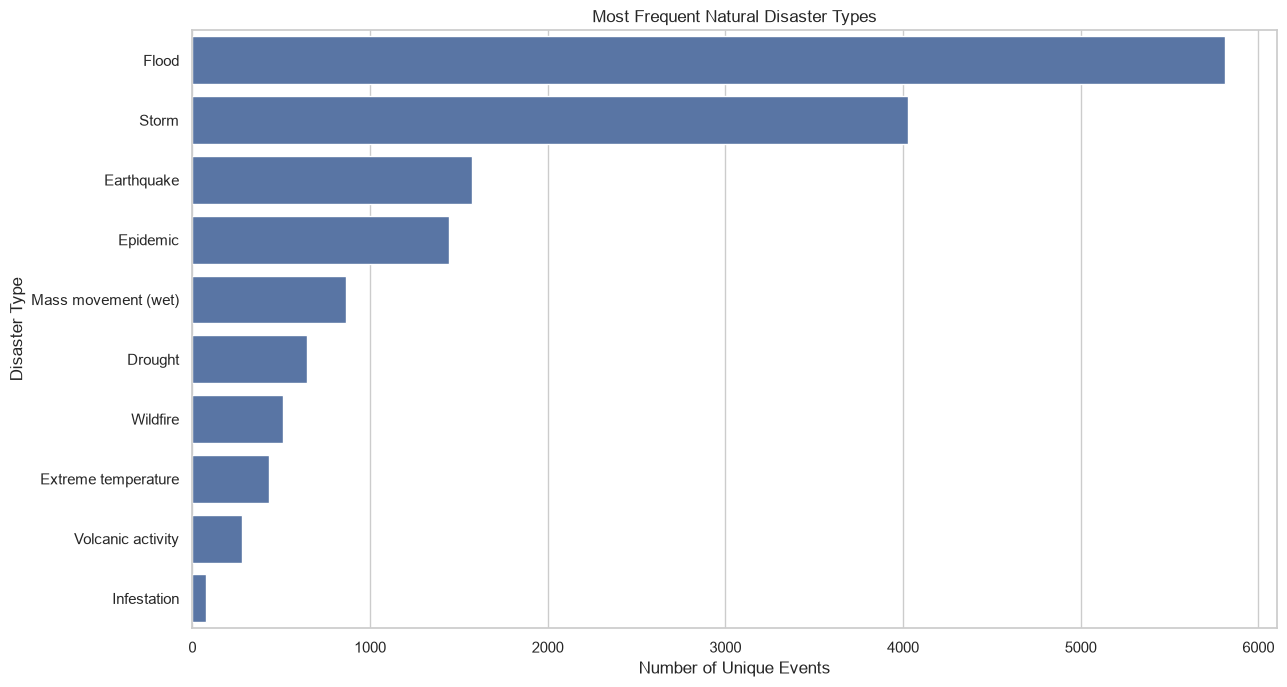

In [3]:
plt.figure(figsize=(13, 7))

sns.barplot(
    data=frequency.head(10),
    x="Unique Events",
    y="Disaster Type"
)

plt.title("Most Frequent Natural Disaster Types")
plt.xlabel("Number of Unique Events")
plt.ylabel("Disaster Type")
plt.tight_layout()

plt.savefig(VIS_DIR / "01_final_disaster_frequency.png", dpi=300)
plt.show()

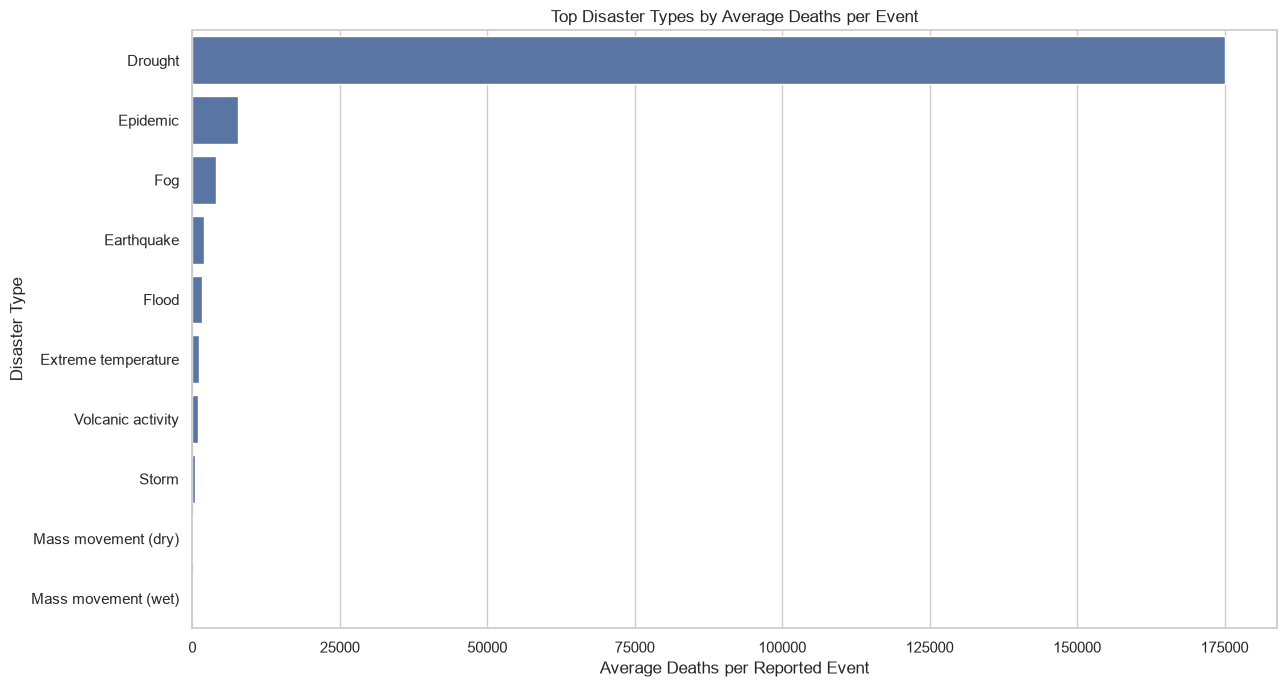

In [4]:
death_data = (
    impact_summary
    .dropna(subset=["Average_Deaths"])
    .sort_values("Average_Deaths", ascending=False)
    .head(10)
)

plt.figure(figsize=(13, 7))

sns.barplot(
    data=death_data,
    x="Average_Deaths",
    y="Disaster Type"
)

plt.title("Top Disaster Types by Average Deaths per Event")
plt.xlabel("Average Deaths per Reported Event")
plt.ylabel("Disaster Type")
plt.tight_layout()

plt.savefig(VIS_DIR / "02_final_average_deaths.png", dpi=300)
plt.show()

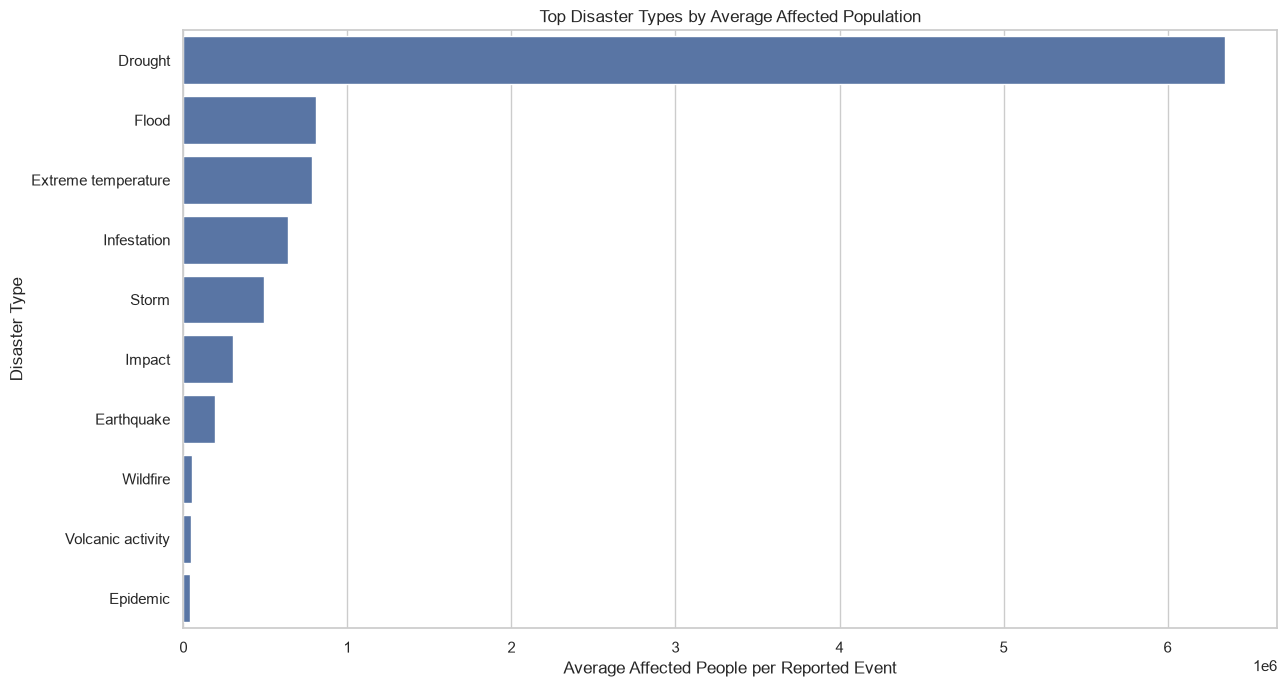

In [5]:
affected_data = (
    impact_summary
    .dropna(subset=["Average_Affected"])
    .sort_values("Average_Affected", ascending=False)
    .head(10)
)

plt.figure(figsize=(13, 7))

sns.barplot(
    data=affected_data,
    x="Average_Affected",
    y="Disaster Type"
)

plt.title("Top Disaster Types by Average Affected Population")
plt.xlabel("Average Affected People per Reported Event")
plt.ylabel("Disaster Type")
plt.tight_layout()

plt.savefig(VIS_DIR / "03_final_average_affected.png", dpi=300)
plt.show()

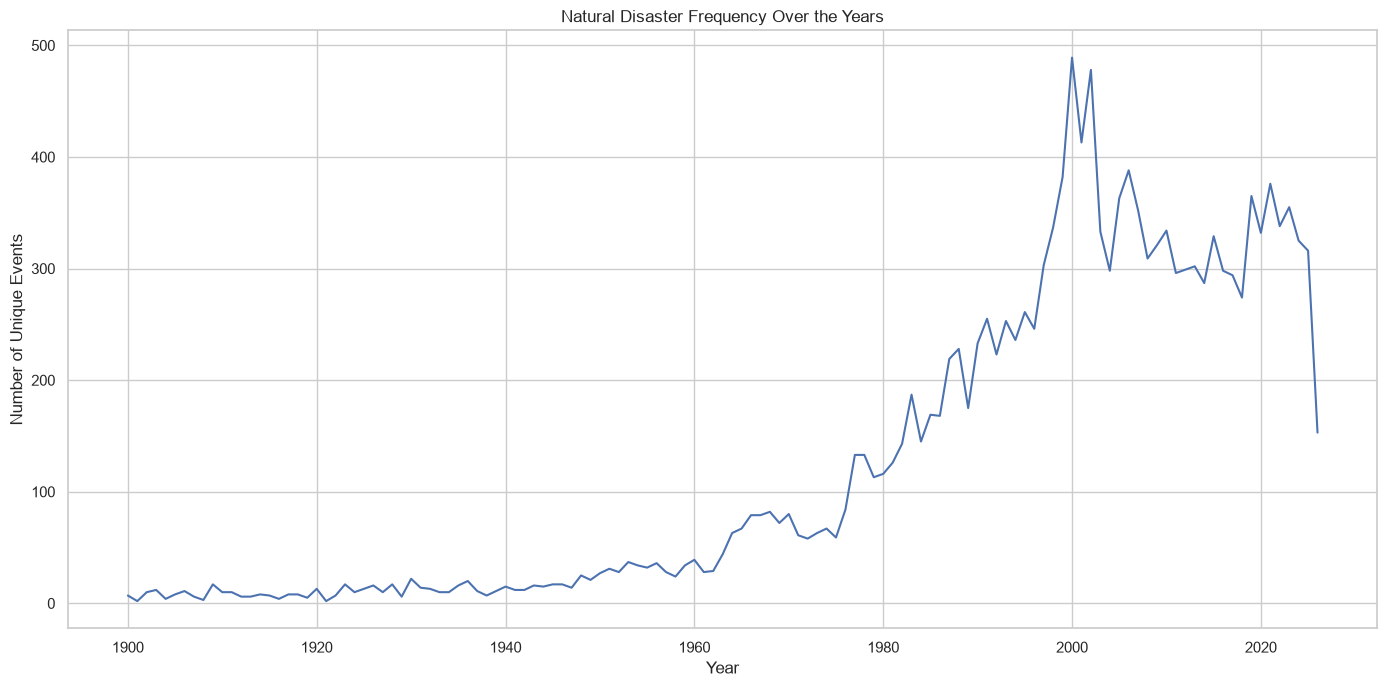

In [6]:
plt.figure(figsize=(14, 7))

sns.lineplot(
    data=yearly_frequency,
    x="Start Year",
    y="Unique Events"
)

plt.title("Natural Disaster Frequency Over the Years")
plt.xlabel("Year")
plt.ylabel("Number of Unique Events")
plt.tight_layout()

plt.savefig(VIS_DIR / "04_final_yearly_trend.png", dpi=300)
plt.show()

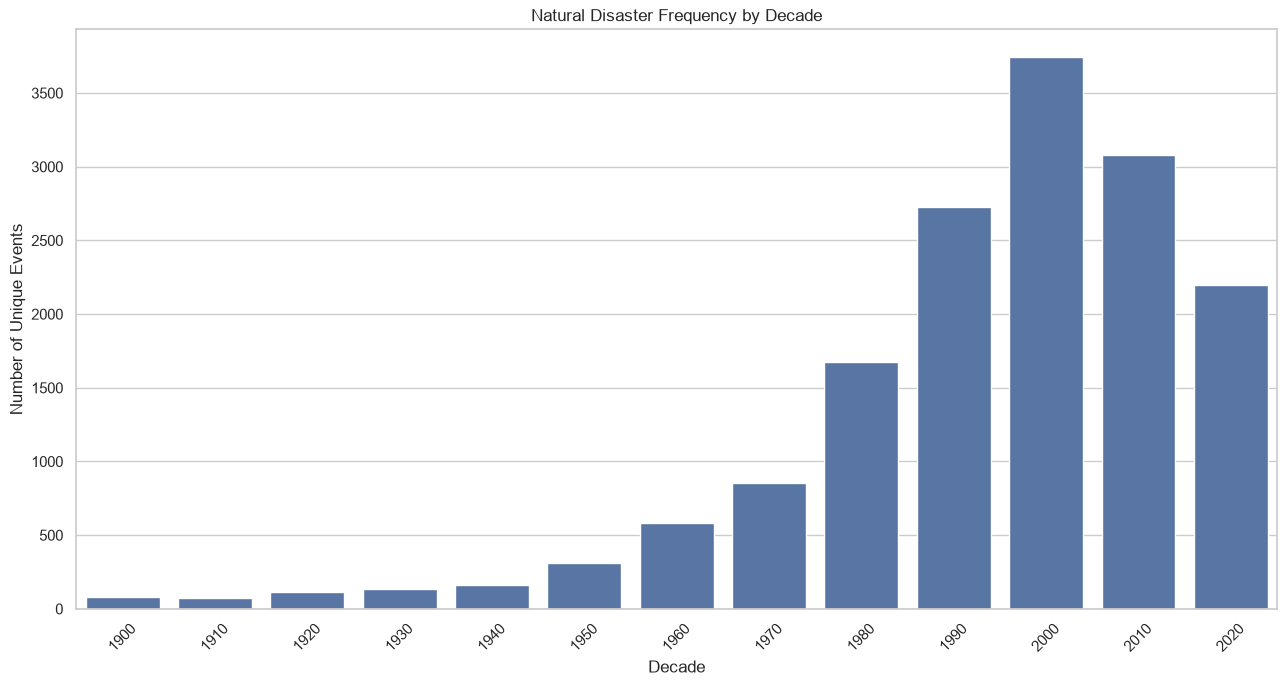

In [7]:
plt.figure(figsize=(13, 7))

sns.barplot(
    data=decadal_frequency,
    x="Decade",
    y="Unique Events"
)

plt.title("Natural Disaster Frequency by Decade")
plt.xlabel("Decade")
plt.ylabel("Number of Unique Events")
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(VIS_DIR / "05_final_decadal_frequency.png", dpi=300)
plt.show()

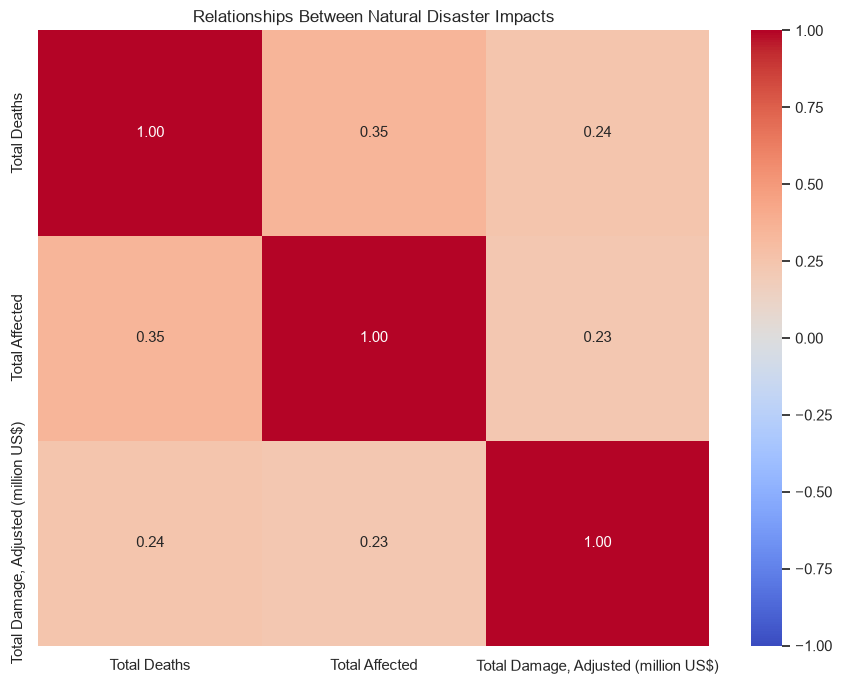

In [8]:
correlation_data = events[
    [
        "Total Deaths",
        "Total Affected",
        "Total Damage, Adjusted (million US$)"
    ]
]

correlation_matrix = correlation_data.corr(method="spearman")

plt.figure(figsize=(9, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Relationships Between Natural Disaster Impacts")
plt.tight_layout()

plt.savefig(VIS_DIR / "06_final_impact_correlation.png", dpi=300)
plt.show()

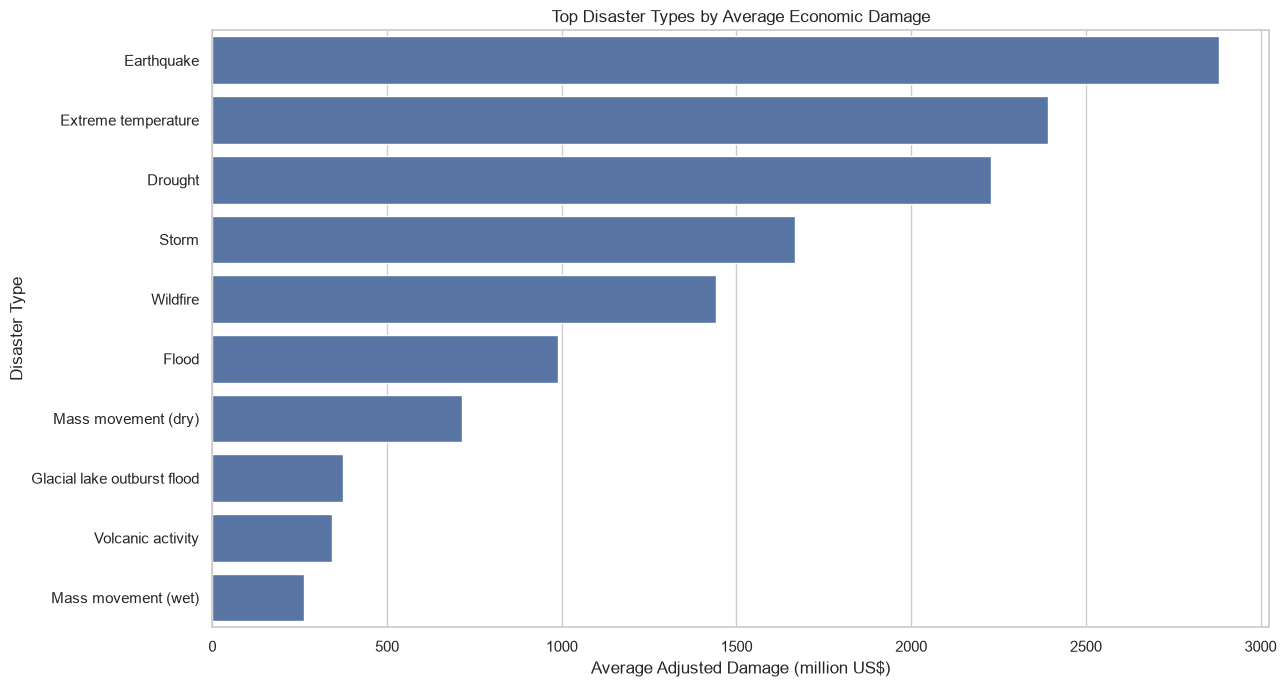

In [9]:
damage_data = (
    impact_summary
    .dropna(subset=["Average_Damage"])
    .sort_values("Average_Damage", ascending=False)
    .head(10)
)

plt.figure(figsize=(13, 7))

sns.barplot(
    data=damage_data,
    x="Average_Damage",
    y="Disaster Type"
)

plt.title("Top Disaster Types by Average Economic Damage")
plt.xlabel("Average Adjusted Damage (million US$)")
plt.ylabel("Disaster Type")
plt.tight_layout()

plt.savefig(VIS_DIR / "07_final_average_damage.png", dpi=300)
plt.show()

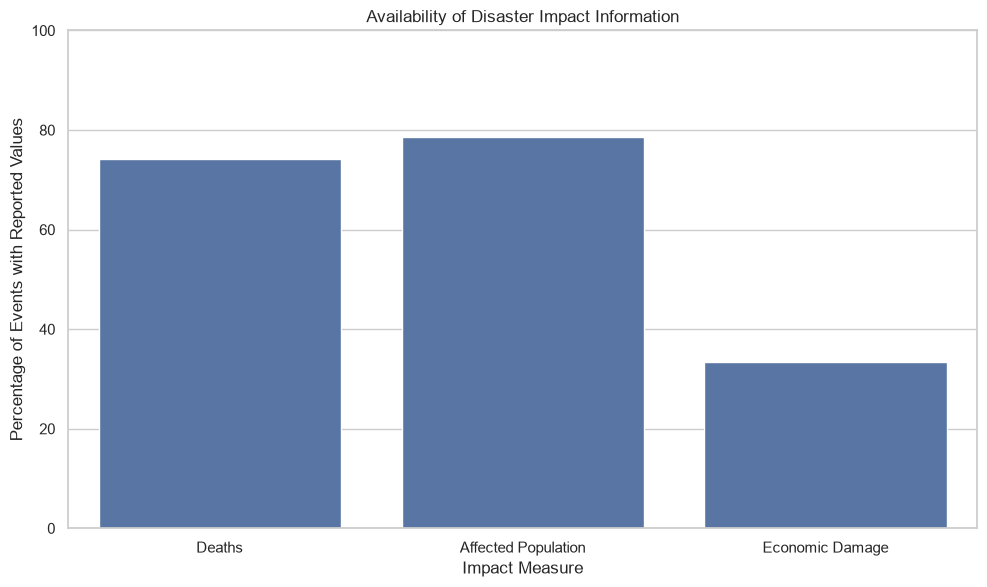

,Impact Measure,Reported Events,Coverage (%)
0,Deaths,11655,74.108222
1,Affected Population,12366,78.629109
2,Economic Damage,5251,33.388440


In [10]:
coverage = pd.DataFrame({
    "Impact Measure": [
        "Deaths",
        "Affected Population",
        "Economic Damage"
    ],
    "Reported Events": [
        events["Total Deaths"].count(),
        events["Total Affected"].count(),
        events["Total Damage, Adjusted (million US$)"].count()
    ]
})

coverage["Coverage (%)"] = (
    coverage["Reported Events"] / len(events) * 100
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=coverage,
    x="Impact Measure",
    y="Coverage (%)"
)

plt.title("Availability of Disaster Impact Information")
plt.xlabel("Impact Measure")
plt.ylabel("Percentage of Events with Reported Values")
plt.ylim(0, 100)
plt.tight_layout()

plt.savefig(VIS_DIR / "08_final_reporting_coverage.png", dpi=300)
plt.show()

display(coverage)

In [11]:
print("========== FINAL PROJECT STATISTICS ==========")

print("\nTotal unique disaster events:")
print(events["Event ID"].nunique())

print("\nMost frequent disaster type:")
print(frequency.iloc[0]["Disaster Type"])
print("Number of events:", frequency.iloc[0]["Unique Events"])

print("\nDisaster type with highest average deaths:")
print(death_data.iloc[0]["Disaster Type"])
print("Average deaths:", round(death_data.iloc[0]["Average_Deaths"], 2))

print("\nDisaster type with highest average affected population:")
print(affected_data.iloc[0]["Disaster Type"])
print("Average affected:", round(affected_data.iloc[0]["Average_Affected"], 2))

print("\nDisaster type with highest average economic damage:")
print(damage_data.iloc[0]["Disaster Type"])
print("Average damage (million US$):", round(damage_data.iloc[0]["Average_Damage"], 2))

print("\nYear with the highest recorded disaster frequency:")
print(int(yearly_frequency.loc[yearly_frequency["Unique Events"].idxmax(), "Start Year"]))

print("\n================================================")

========== FINAL PROJECT STATISTICS ==========

Total unique disaster events:
15727

Most frequent disaster type:
Flood
Number of events: 5814

Disaster type with highest average deaths:
Drought
Average deaths: 175139.6

Disaster type with highest average affected population:
Drought
Average affected: 6349540.46

Disaster type with highest average economic damage:
Earthquake
Average damage (million US$): 2881.02

Year with the highest recorded disaster frequency:
2000



In [12]:
frequency.to_csv(
    OUTPUT_DIR / "final_disaster_frequency.csv",
    index=False
)

impact_summary.to_csv(
    OUTPUT_DIR / "final_disaster_impact_summary.csv",
    index=False
)

yearly_frequency.to_csv(
    OUTPUT_DIR / "final_yearly_frequency.csv",
    index=False
)

decadal_frequency.to_csv(
    OUTPUT_DIR / "final_decadal_frequency.csv",
    index=False
)

coverage.to_csv(
    OUTPUT_DIR / "final_reporting_coverage.csv",
    index=False
)

correlation_matrix.to_csv(
    OUTPUT_DIR / "final_impact_correlation.csv"
)

print("All final summary files exported successfully!")

All final summary files exported successfully!
